In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [12]:
with open("credit.csv") as file:
    df = pd.read_csv(file, sep=",")

In [13]:
cat_cols = ["Gender", "Student", "Married", "Ethnicity"]
for c in cat_cols:
    df[c] = df[c].astype("category")
df = pd.get_dummies(df, drop_first=True)

In [19]:
def evaluate_model(X, y, model):
    kf = KFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(model, X, y, cv=kf, scoring="accuracy")
    return scores


In [36]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "KNN (k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
}

Income > 50, Logistic Regression accuracy: mean=0.9300 std=0.0444
Income > 50, Decision Tree accuracy: mean=0.9075 std=0.0434
Income > 50, Random Forest accuracy: mean=0.8925 std=0.0613
Income > 50, KNN (k=5) accuracy: mean=0.7500 std=0.0652


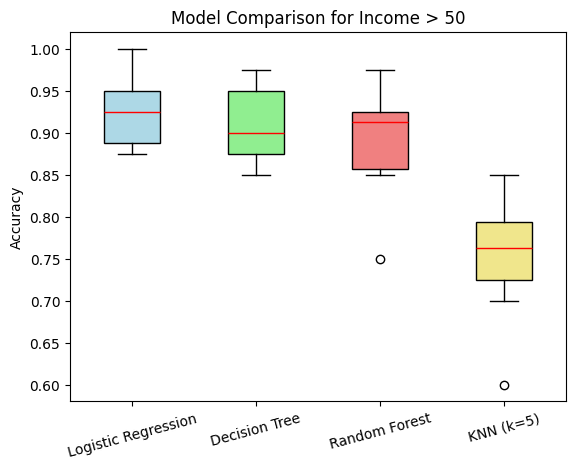

In [37]:
df_a = df.copy()
df_a["HighIncome"] = (df_a["Income"] > 50).astype(bool)
df_a = df_a.drop(columns=["Income"])
X_a = df_a.drop(columns=["HighIncome"])
y_a = df_a["HighIncome"]

scores_models = {}
for name, model in models.items():
    scores = evaluate_model(X_a, y_a, model)
    scores_models[name] = scores
    print(f"Income > 50, {name} accuracy: mean={scores.mean():.4f} std={scores.std():.4f}")

box_colors = ['lightblue', 'lightgreen', 'lightcoral', 'khaki']
boxplot = plt.boxplot(pd.DataFrame(scores_models), patch_artist=True,
                      medianprops=dict(color='red'))
for patch, color in zip(boxplot['boxes'], box_colors):
    patch.set_facecolor(color)
plt.title("Model Comparison for Income > 50")
plt.ylabel("Accuracy")
plt.xticks(range(1, len(scores_models) + 1), list(scores_models.keys()), rotation=15)
plt.show()

Number of credit cards, Logistic Regression accuracy: mean=0.2725 std=0.0810
Number of credit cards, Decision Tree accuracy: mean=0.2150 std=0.0614
Number of credit cards, Random Forest accuracy: mean=0.2825 std=0.0852
Number of credit cards, KNN (k=5) accuracy: mean=0.2375 std=0.0727


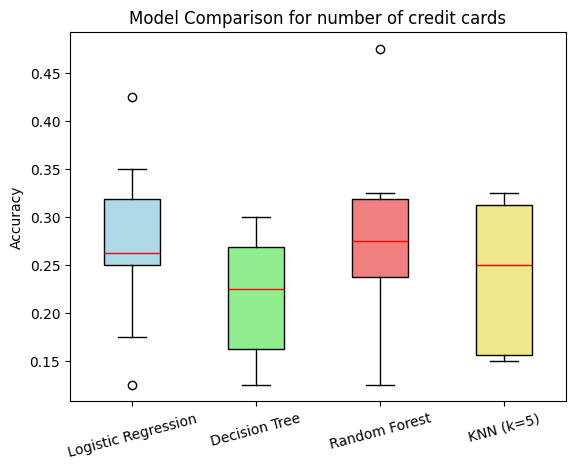

In [39]:
X_b = df.drop(columns=["Cards"])
y_b = df["Cards"]

scores_models = {}
for name, model in models.items():
    scores = evaluate_model(X_b, y_b, model)
    scores_models[name] = scores
    print(f"Number of credit cards, {name} accuracy: mean={scores.mean():.4f} std={scores.std():.4f}")

box_colors = ['lightblue', 'lightgreen', 'lightcoral', 'khaki']
boxplot = plt.boxplot(pd.DataFrame(scores_models), patch_artist=True,
                      medianprops=dict(color='red'))
for patch, color in zip(boxplot['boxes'], box_colors):
    patch.set_facecolor(color)
plt.title("Model Comparison for number of credit cards")
plt.ylabel("Accuracy")
plt.xticks(range(1, len(scores_models) + 1), list(scores_models.keys()), rotation=15)
plt.show()